In [13]:
!git clone -q https://github.com/ihebgafsi/mmWave /kaggle/working/project
!pip -q install plyfile tqdm
%cd /kaggle/working/project

fatal: destination path '/kaggle/working/project' already exists and is not an empty directory.
/kaggle/working/project


In [14]:
!python -m common.build_cache --stage meta

>> meta
{'train': 2781, 'val': 602, 'test': 598} seqs: {'train': [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21], 'val': [10, 12, 16], 'test': [4, 8]}


/kaggle/working/project
vehicle distance percentiles (m): {5: 12.2, 50: 38.5, 95: 50.7, 99: 51.8, 100: 52.2}


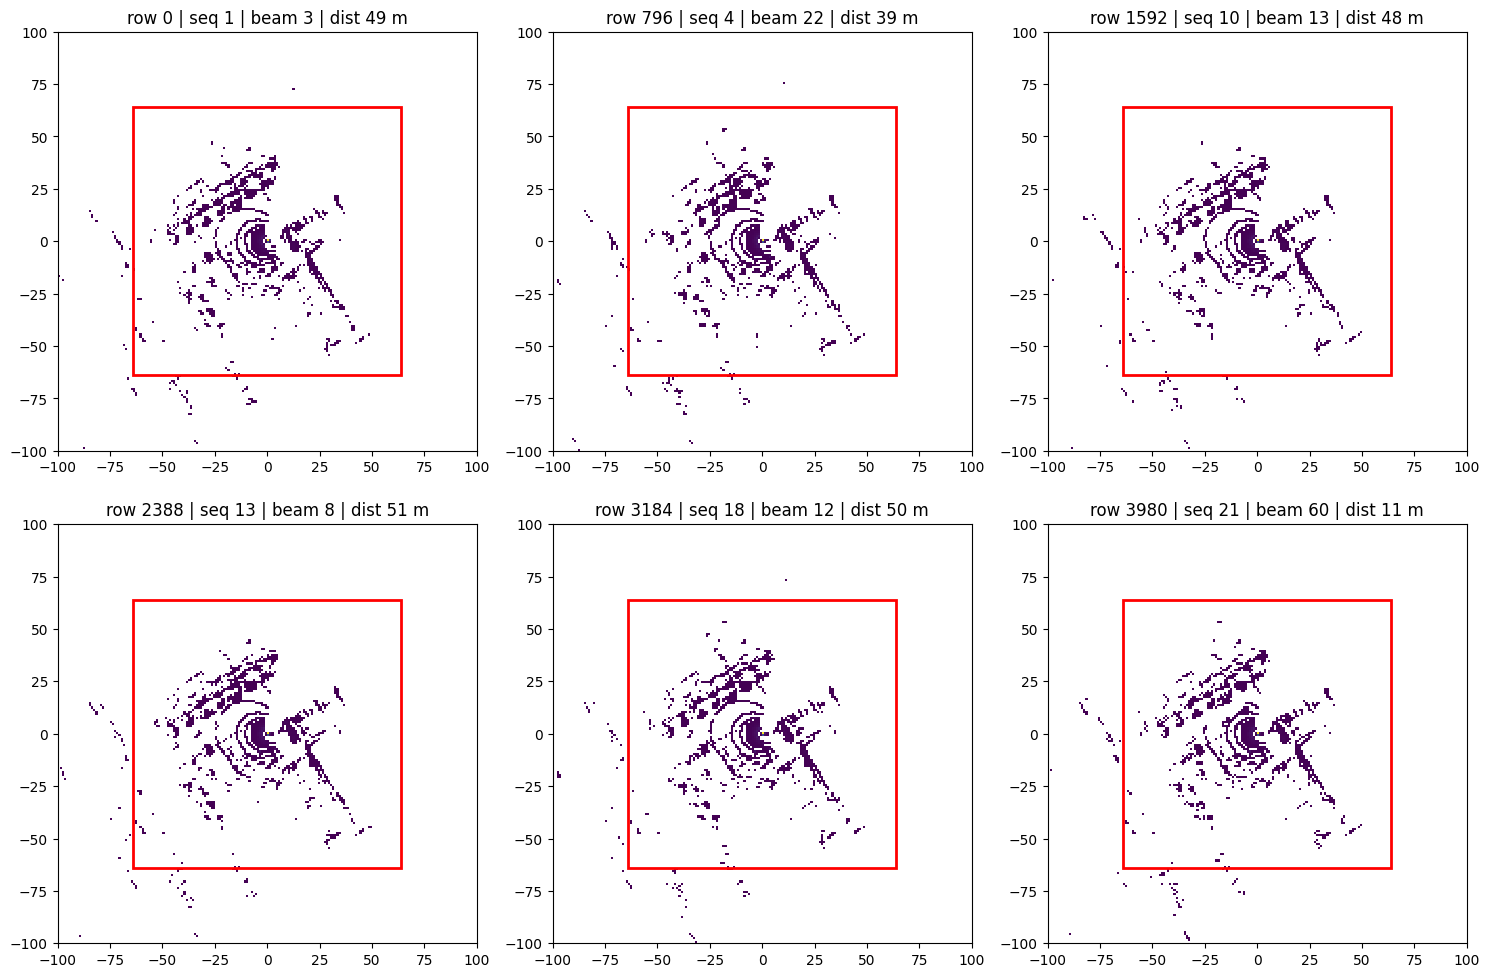

LiDAR point range percentiles (m): {50: 4.8, 90: 27.8, 95: 34.4, 99: 52.1}
share of points inside ±64 m: 0.993


In [15]:
%cd /kaggle/working/project
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import config as C
from common.build_cache import read_ply

m = pd.read_csv(C.WORK / "master.csv")

# 1) How far are the cars from the base station? (GPS distance, metres)
print("vehicle distance percentiles (m):",
      {p: round(float(np.percentile(m.dist_m, p)), 1) for p in (5, 50, 95, 99, 100)})

# 2) What does the LiDAR actually see? 6 scans spread over the dataset
rows = np.linspace(0, len(m) - 1, 6).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
all_r = []
for ax, r in zip(axes.ravel(), rows):
    p = read_ply(C.DATA_ROOT / m.lidar[r]); p = p[np.isfinite(p).all(1)]
    all_r.append(np.hypot(p[:, 0], p[:, 1]))
    ax.hist2d(p[:, 0], p[:, 1], bins=200, range=[[-100, 100], [-100, 100]], cmap="viridis", cmin=1)
    ax.add_patch(plt.Rectangle((-64, -64), 128, 128, fill=False, ec="red", lw=2))   # current BEV window
    ax.set_title(f"row {r} | seq {m.seq[r]} | beam {m.beam[r]} | dist {m.dist_m[r]:.0f} m"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

all_r = np.concatenate(all_r)
print("LiDAR point range percentiles (m):",
      {p: round(float(np.percentile(all_r, p)), 1) for p in (50, 90, 95, 99)})
print("share of points inside ±64 m:", round(float(((all_r < 64)).mean()), 3))

In [16]:
%cd /kaggle/working/project
!python -m common.build_cache --stage lidar
!python -m common.build_cache --stage lidar_pts
!python -m common.sanity

/kaggle/working/project
>> lidar
100%|███████████████████████████████████████| 3981/3981 [08:13<00:00,  8.07it/s]
>> lidar_pts
100%|███████████████████████████████████████| 3981/3981 [06:22<00:00, 10.41it/s]
train 2781 samples | seqs [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21]
val 602 samples | seqs [10, 12, 16]
test 598 samples | seqs [4, 8]
camera     cache missing -> run build_cache --stage camera
radar      cache missing -> run build_cache --stage radar
radar_ra   cache missing -> run build_cache --stage radar_ra
lidar      (3, 128, 128) torch.float32 | label 4 | idx 2036
lidar_pts  (4096, 3) torch.float32 | label 4 | idx 2036
gps        (5,) torch.float32 | label 4 | idx 2036
history/horizon OK: (4, 5)
baselines (test): {'random': {'top1': 0.016, 'top3': 0.047, 'top5': 0.078}, 'majority': {'top1': 0.366, 'top3': 0.418, 'top5': 0.453}, 'exhaustive(64 beams)': {'top1': 1.0, 'top3': 1.0, 'top5': 1.0, 'K90': 64, 'K95': 64, 'overhead': 1.0, 'gain': 0.0}}


active pixels per frame after bg removal: 146.1


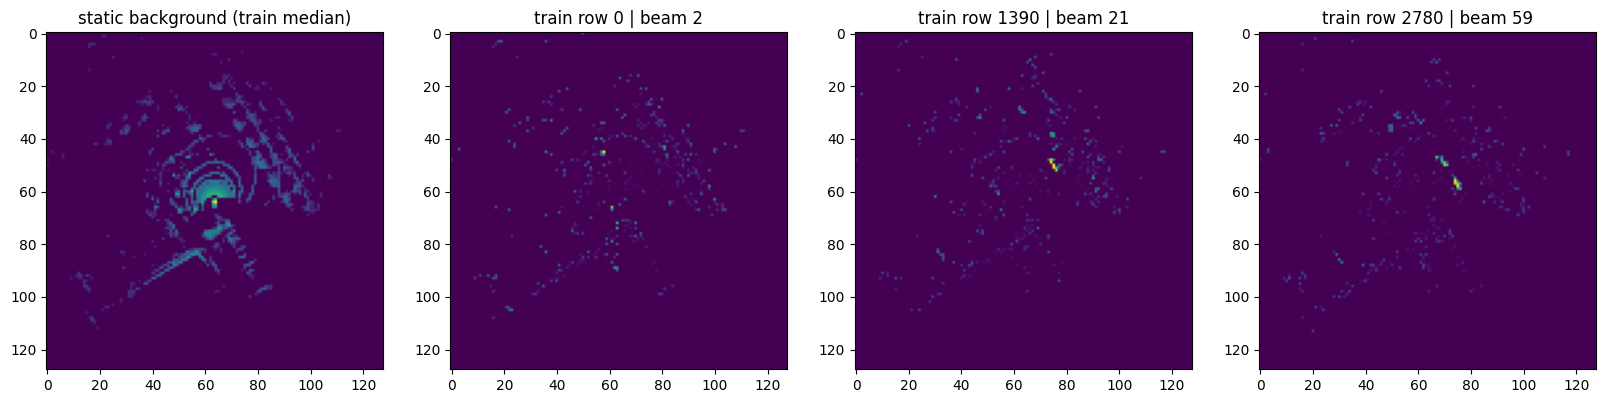

NameError: name 'dev' is not defined

In [17]:
import numpy as np, torch, matplotlib.pyplot as plt
from common.dataset import BeamDataset
tr_ds = BeamDataset("train", ["lidar"])
X = np.stack([tr_ds[i]["lidar"][0].numpy() for i in range(len(tr_ds))])   # density channel, train only
bg = np.median(X, 0)
D = np.clip(X - bg, 0, None)
print("active pixels per frame after bg removal:", round(float((D > 0.5).sum((1, 2)).mean()), 1))
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(bg); ax[0].set_title("static background (train median)")
for a, i in zip(ax[1:], np.linspace(0, len(D) - 1, 3).astype(int)):
    a.imshow(D[i]); a.set_title(f"train row {i} | beam {int(tr_ds[i]['label'])}")
plt.show()
BG = torch.tensor(bg, device=dev, dtype=torch.float32)[None, None]

In [18]:
%cd /kaggle/working/project
!rm -rf results/LID-E1 results/all_results.csv
import time, numpy as np, torch, torch.nn as nn
from common.dataset import BeamDataset, get_loaders
from common.metrics import seed_everything, evaluate, save_results, count_params
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

# ---- static background = median density over TRAIN frames only (no leakage)
tr_ds = BeamDataset("train", ["lidar"])
X = np.stack([tr_ds[i]["lidar"][0].numpy() for i in range(len(tr_ds))])
BG = torch.tensor(np.median(X, 0), device=dev, dtype=torch.float32)[None, None]
print("active pixels/frame after bg removal:", round(float((np.clip(X - np.median(X, 0), 0, None) > 0.5).sum((1, 2)).mean()), 1))
del X

# ---- coordinate channels (CoordConv) so the CNN knows WHERE things are
yy, xx = torch.meshgrid(torch.linspace(-1, 1, 128), torch.linspace(-1, 1, 128), indexing="ij")
COORD = torch.stack([xx, yy])[None].to(dev)

class SmallCNN(nn.Module):
    def __init__(s, cin=3, n=64):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(cin, 32), blk(32, 64), blk(64, 64), blk(64, 64), nn.Flatten())   # 128 -> 8x8, layout kept
        s.emb = nn.Sequential(nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Dropout(0.3))
        s.head = nn.Linear(128, n)
    def embed(s, x): return s.emb(s.f(x))
    def forward(s, x): return s.head(s.embed(x))

def fwd(m, b, d):
    x = torch.relu(b["lidar"][:, 0:1].to(d) - BG)                     # density minus static background
    return m(torch.cat([x, COORD.expand(len(x), -1, -1, -1)], 1))

EXP, CFG = "LID-E1", dict(lr=3e-4, wd=1e-4, epochs=40, bs=64, patience=15,
                          channels="density-bg+coord", pool="flatten8x8", bg="train_median")
tests = []
for seed in (0, 1, 2):
    seed_everything(seed)
    tr, va, te = get_loaders(["lidar"], batch_size=CFG["bs"])
    model = SmallCNN().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["epochs"])
    best, bad, ckpt, t0 = -1, 0, f"/kaggle/working/{EXP}_seed{seed}.pt", time.time()
    for ep in range(CFG["epochs"]):
        model.train(); tot, nb = 0.0, 0
        for b in tr:
            loss = nn.functional.cross_entropy(fwd(model, b, dev), b["label"].to(dev))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); nb += 1
        sch.step()
        vm, _ = evaluate(model, va, dev, forward=fwd)                  # model selection on VAL only
        if vm["top1"] > best: best, bad = vm["top1"], 0; torch.save(model.state_dict(), ckpt)
        else: bad += 1
        print(f"seed {seed} ep {ep:02d} train loss {tot/nb:.3f} | val top1 {vm['top1']:.3f} top3 {vm['top3']:.3f} top5 {vm['top5']:.3f}")
        if bad >= CFG["patience"]: break
    model.load_state_dict(torch.load(ckpt))
    vm, vl = evaluate(model, va, dev, forward=fwd)
    tm, tl = evaluate(model, te, dev, forward=fwd)                     # test: once, at the end
    print(f"== seed {seed} TEST", {k: round(v, 3) for k, v in tm.items() if isinstance(v, float)})
    save_results(EXP, seed, tm, CFG, ckpt, count_params(model), time.time() - t0, val_logits=vl, test_logits=tl)
    tests.append(tm)

print("\n### LID-E1 TEST mean ± std over 3 seeds")
for k in ("top1", "top3", "top5", "pwr_loss_db_top1"):
    v = np.array([t[k] for t in tests]); print(f"{k:18s} {v.mean():.3f} ± {v.std():.3f}")

/kaggle/working/project
device: cuda
active pixels/frame after bg removal: 146.1
seed 0 ep 00 train loss 3.722 | val top1 0.071 top3 0.164 top5 0.266
seed 0 ep 01 train loss 3.474 | val top1 0.055 top3 0.158 top5 0.254
seed 0 ep 02 train loss 3.287 | val top1 0.045 top3 0.133 top5 0.236
seed 0 ep 03 train loss 3.105 | val top1 0.033 top3 0.120 top5 0.226
seed 0 ep 04 train loss 2.952 | val top1 0.045 top3 0.156 top5 0.226
seed 0 ep 05 train loss 2.808 | val top1 0.033 top3 0.151 top5 0.246
seed 0 ep 06 train loss 2.671 | val top1 0.060 top3 0.159 top5 0.248
seed 0 ep 07 train loss 2.535 | val top1 0.073 top3 0.163 top5 0.249
seed 0 ep 08 train loss 2.403 | val top1 0.070 top3 0.154 top5 0.236
seed 0 ep 09 train loss 2.283 | val top1 0.075 top3 0.163 top5 0.233
seed 0 ep 10 train loss 2.162 | val top1 0.075 top3 0.178 top5 0.239
seed 0 ep 11 train loss 2.059 | val top1 0.071 top3 0.171 top5 0.236
seed 0 ep 12 train loss 1.963 | val top1 0.076 top3 0.176 top5 0.243
seed 0 ep 13 train los

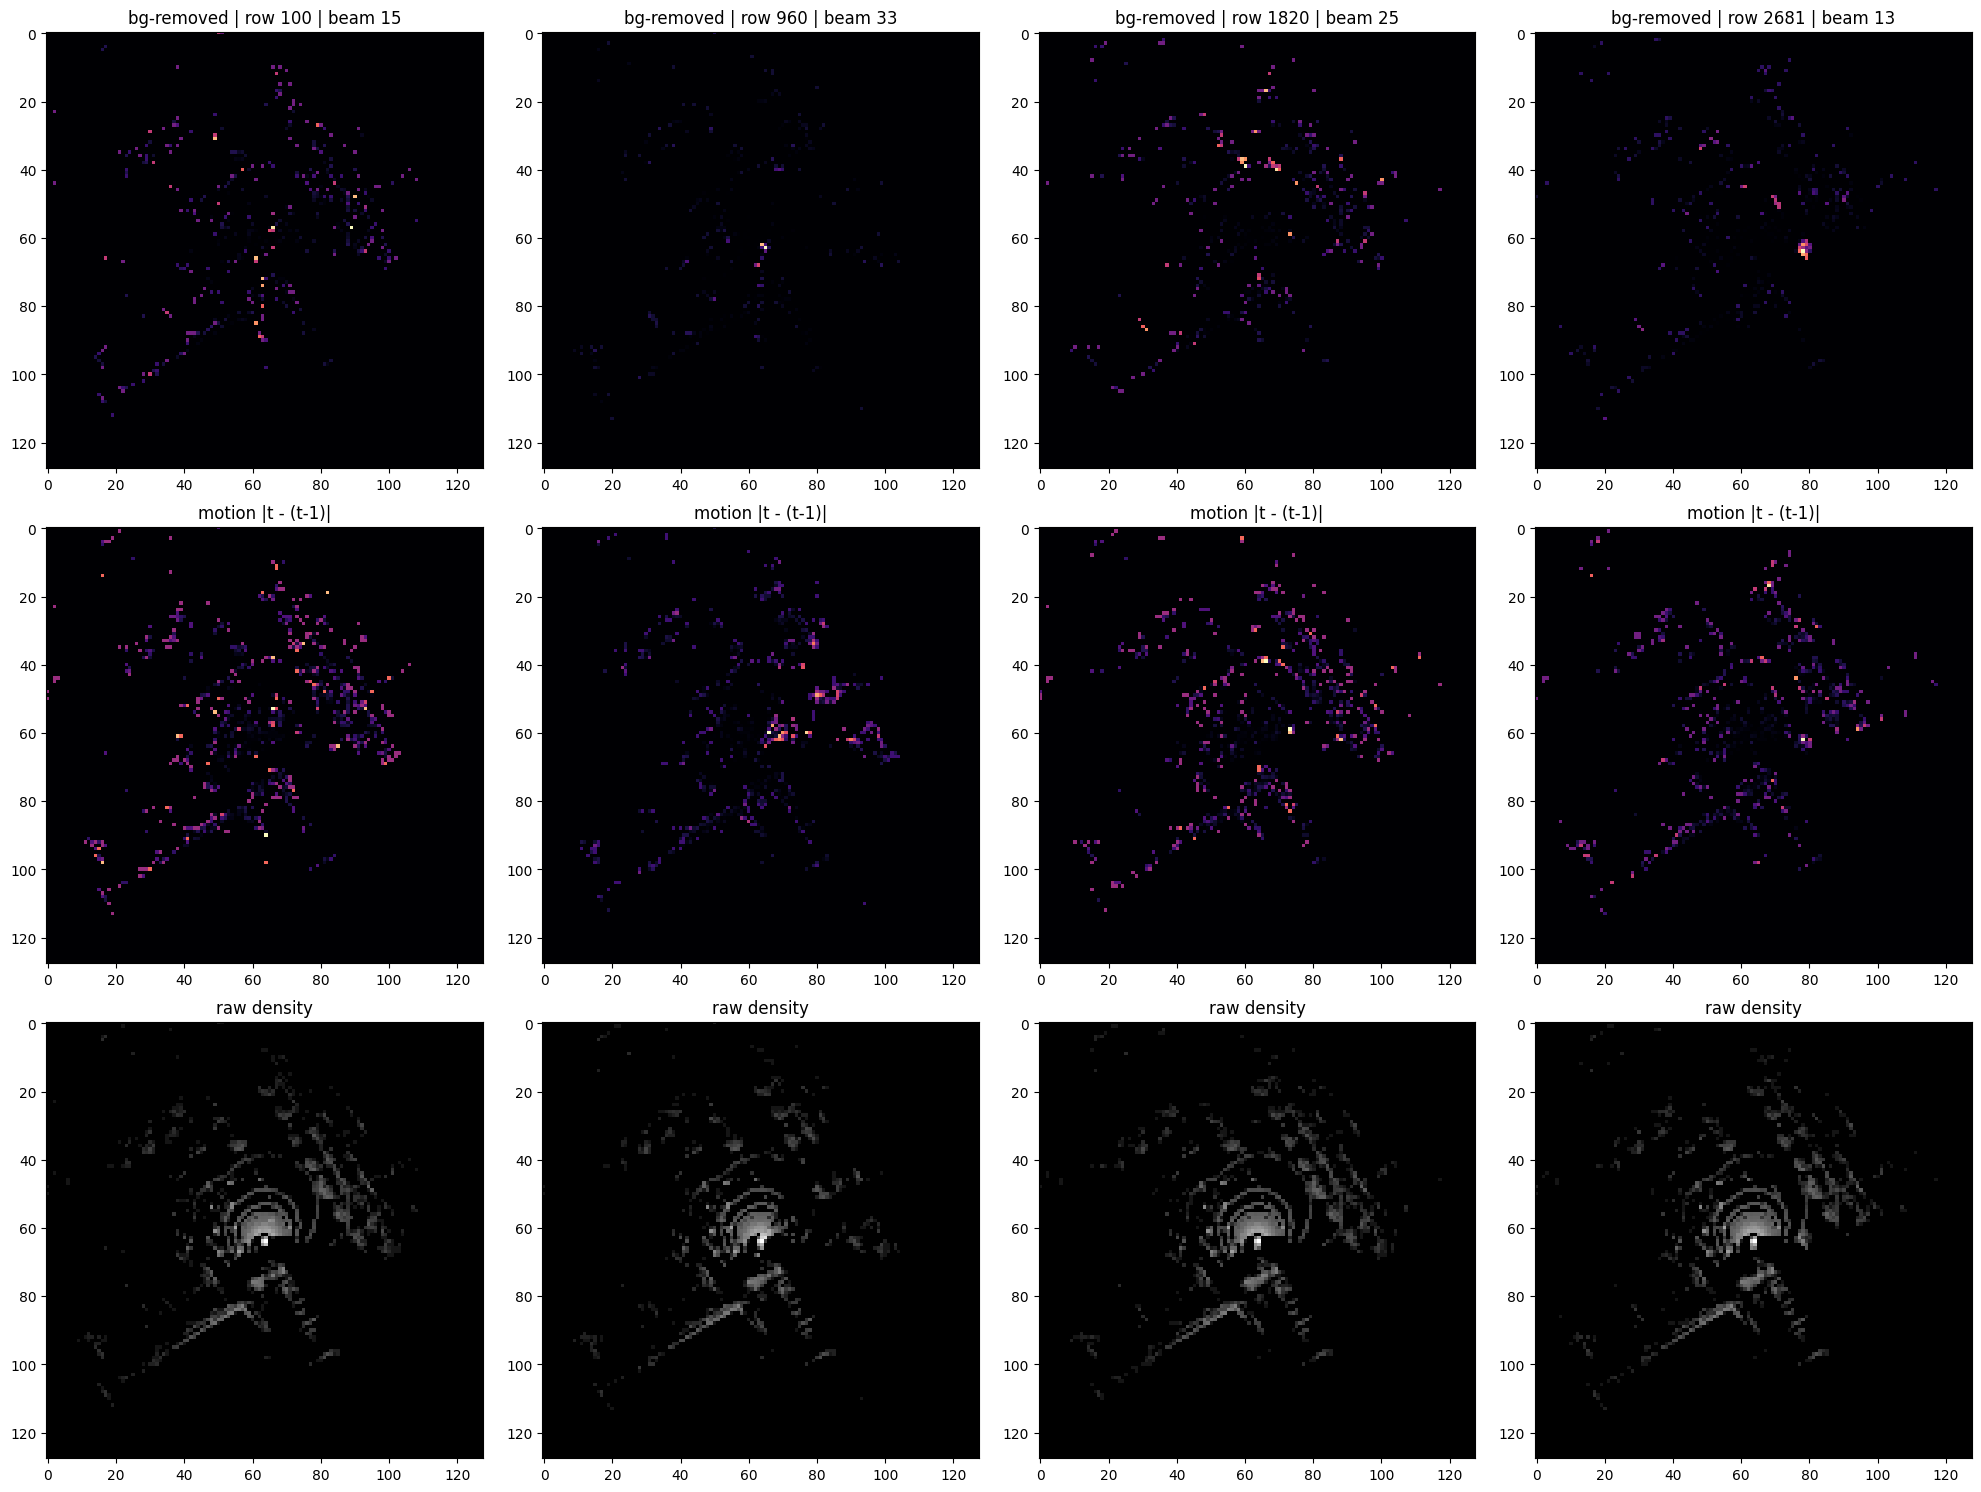

active px/frame  bg-removed: 146.0 | motion: 251.2


In [19]:
import numpy as np, matplotlib.pyplot as plt
from common.dataset import BeamDataset
ds = BeamDataset("train", ["lidar"], history=1)
idx = np.linspace(100, len(ds)-100, 4).astype(int)
S = [ds[i] for i in idx]
bgn = BG[0,0].cpu().numpy()
fig, ax = plt.subplots(3, 4, figsize=(20, 15))
_ = [ax[0,j].imshow(np.clip(S[j]["lidar"][1,0].numpy()-bgn, 0, None), cmap="magma") for j in range(4)]
_ = [ax[1,j].imshow(np.abs(S[j]["lidar"][1,0].numpy()-S[j]["lidar"][0,0].numpy()), cmap="magma") for j in range(4)]
_ = [ax[2,j].imshow(S[j]["lidar"][1,0].numpy(), cmap="gray") for j in range(4)]
_ = [ax[0,j].set_title(f"bg-removed | row {idx[j]} | beam {int(S[j]['label'])}") for j in range(4)]
_ = [ax[1,j].set_title("motion |t - (t-1)|") for j in range(4)]
_ = [ax[2,j].set_title("raw density") for j in range(4)]
plt.tight_layout(); plt.show()
sub = range(0, len(ds), 10)
M = np.stack([np.abs(ds[i]["lidar"][1,0].numpy()-ds[i]["lidar"][0,0].numpy()) for i in sub])
B = np.stack([np.clip(ds[i]["lidar"][1,0].numpy()-bgn, 0, None) for i in sub])
print("active px/frame  bg-removed:", round(float((B>0.5).sum((1,2)).mean()),1), "| motion:", round(float((M>0.5).sum((1,2)).mean()),1))

{'th0.5_k1': 146.0, 'th0.5_k3': 25.3, 'th0.5_k5': 4.5, 'th1.0_k1': 32.9, 'th1.0_k3': 9.3, 'th1.0_k5': 2.0, 'th1.5_k1': 11.4, 'th1.5_k3': 4.1, 'th1.5_k5': 0.6}


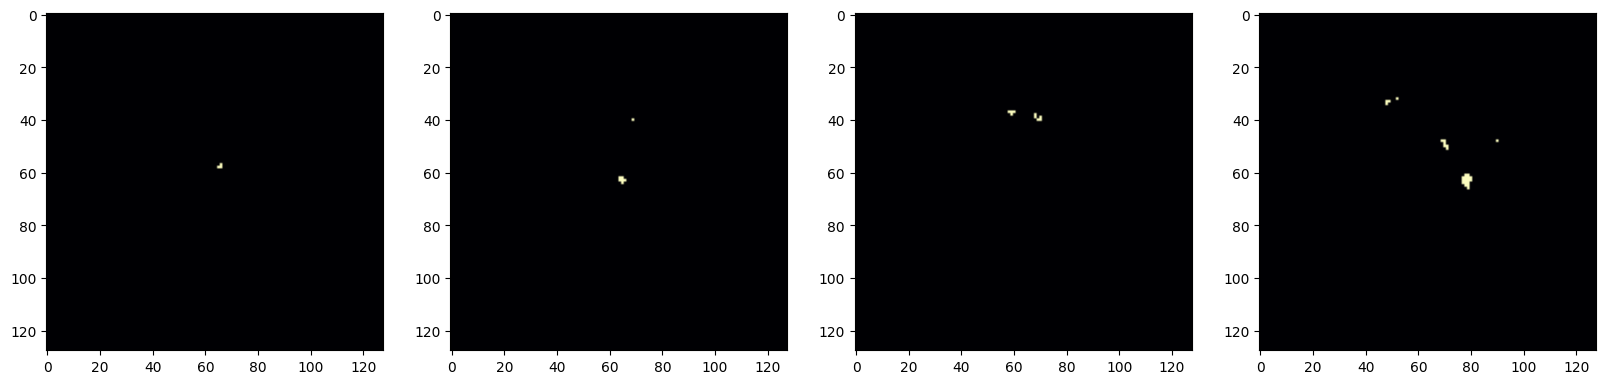

In [20]:
import torch.nn.functional as F
def den(x, th, k): m = (x > th).float(); n = F.avg_pool2d(m[:, None], 3, 1, 1)[:, 0] * 9; return m * (n >= k)
Bt = torch.tensor(B)
print({f"th{th}_k{k}": round(float(den(Bt, th, k).sum((1, 2)).mean()), 1) for th in (0.5, 1.0, 1.5) for k in (1, 3, 5)})
Ds = den(torch.tensor(np.stack([np.clip(S[j]["lidar"][1,0].numpy()-bgn, 0, None) for j in range(4)])), 1.0, 3)
fig, ax = plt.subplots(1, 4, figsize=(20, 5)); _ = [ax[j].imshow(Ds[j], cmap="magma") for j in range(4)]; plt.show()

In [21]:
%cd /kaggle/working/project
!rm -rf results/LID-E2
import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import DataLoader
from common import config as C
from common.dataset import BeamDataset, get_loaders
from common.metrics import seed_everything, evaluate, save_results, count_params
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev)

# ---- static background per channel (TRAIN median) + denoise settings from the diagnostic
tr_ds = BeamDataset("train", ["lidar"])
X = np.stack([tr_ds[i]["lidar"].numpy() for i in range(len(tr_ds))])            # (N,3,128,128)
BG3 = torch.tensor(np.median(X, 0), device=dev, dtype=torch.float32)[None]      # (1,3,128,128)
del X
TH, K = 1.0, 3                                                                   # ~9 px/frame = vehicle-sized blobs
yy, xx = torch.meshgrid(torch.linspace(-1, 1, 128), torch.linspace(-1, 1, 128), indexing="ij")
COORD = torch.stack([xx, yy])[None].to(dev)

def prep(lidar):                                    # (B,3,128,128) -> (B,5,128,128)
    d = torch.relu(lidar[:, 0:1] - BG3[:, 0:1])     # density minus static scene
    m = (d > TH).float()
    m = m * (F.avg_pool2d(m, 3, 1, 1) * 9 >= K)     # drop isolated speckles (LiDAR flicker)
    x = torch.cat([d * m, lidar[:, 1:3] * m], 1)    # moving-object density + its max/mean height
    return torch.cat([x, COORD.expand(len(x), -1, -1, -1)], 1)

def make_model():
    r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
    w = r.conv1.weight.data.mean(1, keepdim=True)                   # average the pretrained RGB filters
    r.conv1 = nn.Conv2d(5, 64, 7, 2, 3, bias=False); r.conv1.weight.data = w.repeat(1, 5, 1, 1) * 0.6
    r.maxpool = nn.Identity()                                       # keep detail: the car is only ~3x3 px
    r.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 64))
    return r

def embed(m, x):                                    # penultimate 512-d features (for fusion)
    x = m.relu(m.bn1(m.conv1(x)))
    x = m.layer4(m.layer3(m.layer2(m.layer1(x))))
    return torch.flatten(m.avgpool(x), 1)

fwd = lambda m, b, d: m(prep(b["lidar"].to(d)))

@torch.no_grad()
def get_emb(model, split):
    model.eval()
    dl = DataLoader(BeamDataset(split, ["lidar"]), batch_size=128, shuffle=False, num_workers=2)
    return torch.cat([embed(model, prep(b["lidar"].to(dev))).cpu() for b in dl]).numpy()

EXP, CFG = "LID-E2", dict(model="resnet18-imagenet", lr=3e-4, wd=1e-2, epochs=30, bs=64, patience=10,
                          label_smoothing=0.1, input="bg-sub+denoise(th1.0,k3) density/zmax/zmean + coord", maxpool="removed")
tests = []
for seed in (0, 1, 2):
    seed_everything(seed)
    tr, va, te = get_loaders(["lidar"], batch_size=CFG["bs"])
    model = make_model().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["epochs"])
    best, bad, ckpt, t0 = -1, 0, f"/kaggle/working/{EXP}_seed{seed}.pt", time.time()
    for ep in range(CFG["epochs"]):
        model.train(); tot, nb = 0.0, 0
        for b in tr:
            loss = F.cross_entropy(fwd(model, b, dev), b["label"].to(dev), label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); nb += 1
        sch.step()
        vm, _ = evaluate(model, va, dev, forward=fwd)                     # model selection on VAL only
        if vm["top1"] > best: best, bad = vm["top1"], 0; torch.save(model.state_dict(), ckpt)
        else: bad += 1
        print(f"seed {seed} ep {ep:02d} train loss {tot/nb:.3f} | val top1 {vm['top1']:.3f} top3 {vm['top3']:.3f} top5 {vm['top5']:.3f}")
        if bad >= CFG["patience"]: break
    model.load_state_dict(torch.load(ckpt))
    vm, vl = evaluate(model, va, dev, forward=fwd)
    tm, tl = evaluate(model, te, dev, forward=fwd)                        # test: once, at the end
    print(f"== seed {seed} TEST", {k: round(v, 3) for k, v in tm.items() if isinstance(v, float)})
    save_results(EXP, seed, tm, CFG, ckpt, count_params(model), time.time() - t0,
                 val_logits=vl, test_logits=tl, embeddings=get_emb(model, "test"))
    for sp in ("train", "val"):                                           # extra embeddings for the fusion phase
        np.save(C.RESULTS / EXP / f"seed{seed}_emb_{sp}.npy", get_emb(model, sp))
    tests.append(tm)

print("\n### LID-E2 TEST mean ± std over 3 seeds")
for k in ("top1", "top3", "top5", "pwr_loss_db_top1"):
    v = np.array([t[k] for t in tests]); print(f"{k:18s} {v.mean():.3f} ± {v.std():.3f}")

/kaggle/working/project
device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


seed 0 ep 00 train loss 3.530 | val top1 0.070 top3 0.181 top5 0.289
seed 0 ep 01 train loss 2.969 | val top1 0.081 top3 0.171 top5 0.266
seed 0 ep 02 train loss 2.678 | val top1 0.075 top3 0.199 top5 0.256
seed 0 ep 03 train loss 2.486 | val top1 0.073 top3 0.201 top5 0.302
seed 0 ep 04 train loss 2.350 | val top1 0.083 top3 0.216 top5 0.304
seed 0 ep 05 train loss 2.238 | val top1 0.080 top3 0.191 top5 0.267
seed 0 ep 06 train loss 2.142 | val top1 0.095 top3 0.209 top5 0.287
seed 0 ep 07 train loss 2.049 | val top1 0.080 top3 0.214 top5 0.291
seed 0 ep 08 train loss 1.955 | val top1 0.081 top3 0.196 top5 0.279
seed 0 ep 09 train loss 1.862 | val top1 0.070 top3 0.194 top5 0.271
seed 0 ep 10 train loss 1.763 | val top1 0.083 top3 0.206 top5 0.276
seed 0 ep 11 train loss 1.693 | val top1 0.085 top3 0.193 top5 0.276
seed 0 ep 12 train loss 1.593 | val top1 0.061 top3 0.193 top5 0.279
seed 0 ep 13 train loss 1.525 | val top1 0.065 top3 0.191 top5 0.261
seed 0 ep 14 train loss 1.468 | va

In [22]:
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from scipy.stats import spearmanr
from common import config as C
from common.dataset import BeamDataset
master = pd.read_csv(C.WORK / "master.csv")[["idx", "bearing_deg", "dist_m"]]

@torch.no_grad()
def blob_feats(split):
    ds, out = BeamDataset(split, ["lidar"]), []
    for i in range(len(ds)):
        b = ds[i]; x = b["lidar"][None].to(dev)
        d = torch.relu(x[:, 0:1] - BG3[:, 0:1]); m = (d > TH).float(); m = m * (F.avg_pool2d(m, 3, 1, 1) * 9 >= K)
        w = (d * m)[0, 0].cpu().numpy(); s = w.sum()
        r, c = np.indices(w.shape)
        cy, cx = ((r * w).sum() / s, (c * w).sum() / s) if s > 0 else (np.nan, np.nan)
        out.append((cy, cx, int(b["label"]), b["idx"]))
    f = pd.DataFrame(out, columns=["cy", "cx", "beam", "idx"]).merge(master, on="idx")
    f["ang"] = np.degrees(np.arctan2(f.cy - 64, f.cx - 64)); f["rng"] = np.hypot(f.cy - 64, f.cx - 64)
    return f

for sp in ("train", "val", "test"):
    f = blob_feats(sp); g = f.dropna()
    sr = lambda a, b: round(float(spearmanr(g[a], g[b])[0]), 2)
    ang360 = (g.ang % 360)
    best_ang_beam = max(abs(sr("ang", "beam")), abs(round(float(spearmanr(ang360, g.beam)[0]), 2)))
    print(f"{sp:5s} | no-blob frames {f.cy.isna().mean():.0%} | corr(blob angle, beam) {best_ang_beam} | "
          f"corr(blob angle, GPS bearing) {sr('ang', 'bearing_deg')} | corr(blob range, GPS distance) {sr('rng', 'dist_m')}")

train | no-blob frames 7% | corr(blob angle, beam) 0.15 | corr(blob angle, GPS bearing) -0.04 | corr(blob range, GPS distance) 0.19
val   | no-blob frames 16% | corr(blob angle, beam) 0.22 | corr(blob angle, GPS bearing) 0.22 | corr(blob range, GPS distance) 0.41
test  | no-blob frames 4% | corr(blob angle, beam) 0.4 | corr(blob angle, GPS bearing) 0.42 | corr(blob range, GPS distance) 0.54


In [23]:
%cd /kaggle/working/project
!rm -rf results/LID-E3
import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from common.dataset import get_loaders
from common.metrics import seed_everything, evaluate, save_results, count_params
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev)

class PointNet(nn.Module):
    """Shared per-point MLP -> symmetric max-pool -> classifier (Qi et al. 2017, no T-Net)."""
    def __init__(s, n=64):
        super().__init__()
        c = lambda i, o: nn.Sequential(nn.Conv1d(i, o, 1), nn.BatchNorm1d(o), nn.ReLU())
        s.feat = nn.Sequential(c(3, 64), c(64, 128), c(128, 256), c(256, 512))
        s.emb = nn.Sequential(nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.4))
        s.head = nn.Linear(256, n)
    def embed(s, p):                                   # p: (B, N, 3), already scaled to [-1, 1]
        return s.emb(s.feat(p.transpose(1, 2)).max(2).values)
    def forward(s, p): return s.head(s.embed(p))

def fwd(m, b, d):
    p = b["lidar_pts"].to(d)
    if m.training: p = p + 0.005 * torch.randn_like(p)  # small jitter only; NO rotation/flip (would change the beam)
    return m(p)

EXP, CFG = "LID-E3", dict(model="pointnet(no T-Net)", points=4096, lr=1e-3, wd=1e-4, epochs=30, bs=32,
                          patience=10, label_smoothing=0.1, aug="jitter 0.005", input="raw points (no bg removal)")
tests = []
for seed in (0, 1, 2):
    seed_everything(seed)
    tr, va, te = get_loaders(["lidar_pts"], batch_size=CFG["bs"])
    model = PointNet().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["epochs"])
    best, bad, ckpt, t0 = -1, 0, f"/kaggle/working/{EXP}_seed{seed}.pt", time.time()
    for ep in range(CFG["epochs"]):
        model.train(); tot, nb = 0.0, 0
        for b in tr:
            loss = F.cross_entropy(fwd(model, b, dev), b["label"].to(dev), label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); nb += 1
        sch.step()
        vm, _ = evaluate(model, va, dev, forward=fwd)                 # model selection on VAL only
        if vm["top1"] > best: best, bad = vm["top1"], 0; torch.save(model.state_dict(), ckpt)
        else: bad += 1
        print(f"seed {seed} ep {ep:02d} train loss {tot/nb:.3f} | val top1 {vm['top1']:.3f} top3 {vm['top3']:.3f} top5 {vm['top5']:.3f}")
        if bad >= CFG["patience"]: break
    model.load_state_dict(torch.load(ckpt))
    vm, vl = evaluate(model, va, dev, forward=fwd)
    tm, tl = evaluate(model, te, dev, forward=fwd)                    # test: once, at the end
    print(f"== seed {seed} TEST", {k: round(v, 3) for k, v in tm.items() if isinstance(v, float)})
    save_results(EXP, seed, tm, CFG, ckpt, count_params(model), time.time() - t0, val_logits=vl, test_logits=tl)
    tests.append(tm)

print("\n### LID-E3 TEST mean ± std over 3 seeds")
for k in ("top1", "top3", "top5", "pwr_loss_db_top1"):
    v = np.array([t[k] for t in tests]); print(f"{k:18s} {v.mean():.3f} ± {v.std():.3f}")

/kaggle/working/project
device: cuda
seed 0 ep 00 train loss 3.864 | val top1 0.088 top3 0.186 top5 0.301
seed 0 ep 01 train loss 3.716 | val top1 0.086 top3 0.143 top5 0.223
seed 0 ep 02 train loss 3.677 | val top1 0.078 top3 0.199 top5 0.244
seed 0 ep 03 train loss 3.614 | val top1 0.086 top3 0.166 top5 0.254
seed 0 ep 04 train loss 3.568 | val top1 0.043 top3 0.146 top5 0.213
seed 0 ep 05 train loss 3.556 | val top1 0.043 top3 0.141 top5 0.209
seed 0 ep 06 train loss 3.525 | val top1 0.086 top3 0.153 top5 0.229
seed 0 ep 07 train loss 3.468 | val top1 0.045 top3 0.154 top5 0.211
seed 0 ep 08 train loss 3.438 | val top1 0.060 top3 0.136 top5 0.233
seed 0 ep 09 train loss 3.395 | val top1 0.055 top3 0.164 top5 0.248
seed 0 ep 10 train loss 3.351 | val top1 0.040 top3 0.131 top5 0.229
== seed 0 TEST {'top1': 0.366, 'overhead_top1': 0.016, 'gain_top1': 0.984, 'top3': 0.428, 'overhead_top3': 0.047, 'gain_top3': 0.953, 'top5': 0.487, 'overhead_top5': 0.078, 'gain_top5': 0.922, 'overhead_K

In [24]:
import numpy as np, torch
from common.dataset import BeamDataset
from common.metrics import metrics_from_logits
from common import config as C
va = BeamDataset("val", ["gps"])                                         # any modality: only labels/power needed
Y = torch.tensor([int(va[i]["label"]) for i in range(len(va))]); P = torch.stack([va[i]["power"] for i in range(len(va))])
for e in ("LID-E1", "LID-E2", "LID-E3"):
    r = [metrics_from_logits(torch.tensor(np.load(C.RESULTS / e / f"seed{s}_val_logits.npy")), Y, P) for s in (0, 1, 2)]
    print(e, {k: f"{np.mean([x[k] for x in r]):.3f}" for k in ("top1", "top3", "top5")})

LID-E1 {'top1': '0.096', 'top3': '0.190', 'top5': '0.264'}
LID-E2 {'top1': '0.102', 'top3': '0.216', 'top5': '0.298'}
LID-E3 {'top1': '0.089', 'top3': '0.169', 'top5': '0.256'}


In [25]:
%cd /kaggle/working/project
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchvision, shutil
from torch.utils.data import DataLoader
from IPython.display import FileLink
from common import config as C
from common.dataset import BeamDataset
dev = "cuda" if torch.cuda.is_available() else "cpu"

# ---- same preprocessing as LID-E2 (background = TRAIN median, denoise th=1.0 k=3, + coord channels)
tr_ds = BeamDataset("train", ["lidar"])
BG3 = torch.tensor(np.median(np.stack([tr_ds[i]["lidar"].numpy() for i in range(len(tr_ds))]), 0),
                   device=dev, dtype=torch.float32)[None]
TH, K = 1.0, 3
yy, xx = torch.meshgrid(torch.linspace(-1, 1, 128), torch.linspace(-1, 1, 128), indexing="ij")
COORD = torch.stack([xx, yy])[None].to(dev)
def prep(lidar):
    d = torch.relu(lidar[:, 0:1] - BG3[:, 0:1]); m = (d > TH).float()
    m = m * (F.avg_pool2d(m, 3, 1, 1) * 9 >= K)
    return torch.cat([d * m, lidar[:, 1:3] * m, COORD.expand(len(d), -1, -1, -1)], 1)
def make_model():
    r = torchvision.models.resnet18(weights=None)
    r.conv1 = nn.Conv2d(5, 64, 7, 2, 3, bias=False); r.maxpool = nn.Identity()
    r.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 64)); return r
def embed(m, x):
    x = m.relu(m.bn1(m.conv1(x))); x = m.layer4(m.layer3(m.layer2(m.layer1(x))))
    return torch.flatten(m.avgpool(x), 1)

# ---- export: seed{s}_emb_{split}.npy (512-d), seed{s}_logits_{split}.npy (64), seed{s}_idx_{split}.npy
EXP = "LID-E2"; out = C.RESULTS / EXP; out.mkdir(parents=True, exist_ok=True)
for seed in (0, 1, 2):
    model = make_model().to(dev)
    model.load_state_dict(torch.load(f"/kaggle/working/{EXP}_seed{seed}.pt", map_location=dev)); model.eval()
    for sp in ("train", "val", "test"):
        dl = DataLoader(BeamDataset(sp, ["lidar"]), batch_size=128, shuffle=False, num_workers=2)
        E, L, I = [], [], []
        with torch.no_grad():
            for b in dl:
                x = prep(b["lidar"].to(dev)); E.append(embed(model, x).cpu()); L.append(model(x).cpu()); I.append(b["idx"])
        np.save(out / f"seed{seed}_emb_{sp}.npy", torch.cat(E).numpy())
        np.save(out / f"seed{seed}_logits_{sp}.npy", torch.cat(L).numpy())
        np.save(out / f"seed{seed}_idx_{sp}.npy", torch.cat(I).numpy())
        print(f"seed {seed} {sp:5s}: emb {tuple(torch.cat(E).shape)}  logits {tuple(torch.cat(L).shape)}")

shutil.make_archive("/kaggle/working/LID-E2_results", "zip", out)
%cd /kaggle/working
FileLink("LID-E2_results.zip")

/kaggle/working/project
seed 0 train: emb (2781, 512)  logits (2781, 64)
seed 0 val  : emb (602, 512)  logits (602, 64)
seed 0 test : emb (598, 512)  logits (598, 64)
seed 1 train: emb (2781, 512)  logits (2781, 64)
seed 1 val  : emb (602, 512)  logits (602, 64)
seed 1 test : emb (598, 512)  logits (598, 64)
seed 2 train: emb (2781, 512)  logits (2781, 64)
seed 2 val  : emb (602, 512)  logits (602, 64)
seed 2 test : emb (598, 512)  logits (598, 64)
/kaggle/working


/kaggle/working/LID-E2_results.zip

In [26]:
import shutil; from IPython.display import FileLink
shutil.make_archive("/kaggle/working/LiDAR_all_results", "zip", "/kaggle/working/project/results")
%cd /kaggle/working
FileLink("LiDAR_all_results.zip")

/kaggle/working


/kaggle/working/LiDAR_all_results.zip

In [28]:
%cd /kaggle/working/project
import glob, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from common import config as C
from common.dataset import BeamDataset
from common.metrics import seed_everything, metrics_from_logits, save_results
dev = "cuda" if torch.cuda.is_available() else "cpu"
SPLITS = ("train", "val", "test")
GPS_DIR = Path(glob.glob("/kaggle/input/**/GPS-E3", recursive=True)[0]); print("GPS embeddings from:", GPS_DIR)
LID_DIR = C.RESULTS / "LID-E2"

# ---- labels / power / idx in BeamDataset order + alignment check against both teammates' files
ref = {}
for sp in SPLITS:
    ds = BeamDataset(sp, ["gps"]); items = [ds[i] for i in range(len(ds))]
    ref[sp] = dict(idx=np.array([b["idx"] for b in items]), y=torch.tensor([int(b["label"]) for b in items]),
                   p=torch.stack([b["power"] for b in items]))
    assert (np.load(GPS_DIR / f"{sp}_idx.npy") == ref[sp]["idx"]).all(), f"GPS rows misaligned in {sp}"
    f = LID_DIR / f"seed0_idx_{sp}.npy"
    if f.exists(): assert (np.load(f) == ref[sp]["idx"]).all(), f"LiDAR rows misaligned in {sp}"
print("alignment OK:", {sp: len(ref[sp]["idx"]) for sp in SPLITS})

def lid_file(seed, sp):
    f = LID_DIR / f"seed{seed}_emb_{sp}.npy"
    if f.exists(): return f
    assert sp == "test", f"missing {f}"; return LID_DIR / f"seed{seed}_embeddings.npy"   # older name for test emb

def load_emb(seed):
    raw = {"lidar": {sp: np.load(lid_file(seed, sp)) for sp in SPLITS},
           "gps":   {sp: np.load(GPS_DIR / f"seed{seed}_{sp}_emb.npy") for sp in SPLITS}}
    out = {}
    for m, D in raw.items():
        for sp in SPLITS: assert len(D[sp]) == len(ref[sp]["idx"]), f"{m} {sp}: wrong row count"
        mu, sd = D["train"].mean(0), D["train"].std(0) + 1e-6                     # standardize with TRAIN stats only
        out[m] = {sp: torch.tensor((D[sp] - mu) / sd, dtype=torch.float32) for sp in SPLITS}
    return out

class XAttnFusion(nn.Module):
    """One token per modality + learnable [CLS]; transformer attention across modality tokens."""
    def __init__(s, dims, d=128, heads=4, layers=2, mod_drop=0.3, n=64):
        super().__init__()
        s.names, s.p = list(dims), mod_drop
        s.proj = nn.ModuleDict({k: nn.Sequential(nn.Linear(v, d), nn.LayerNorm(d)) for k, v in dims.items()})
        s.mod_emb = nn.Parameter(torch.zeros(len(dims), d)); s.cls = nn.Parameter(torch.zeros(1, 1, d))
        s.mask_tok = nn.Parameter(torch.zeros(d))
        s.att = nn.ModuleList([nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True) for _ in range(layers)])
        s.ln = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
        s.ffn = nn.ModuleList([nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(0.1),
                                             nn.Linear(2 * d, d)) for _ in range(layers)])
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.3), nn.Linear(d, n))
    def forward(s, xs, return_attn=False):
        B = next(iter(xs.values())).shape[0]
        toks = torch.stack([s.proj[k](xs[k]) + s.mod_emb[j] for j, k in enumerate(s.names)], 1)    # (B, M, d)
        if s.training and s.p > 0 and len(s.names) > 1:                                            # modality dropout
            drop = torch.rand(B, len(s.names), 1, device=toks.device) < s.p
            drop[drop.all(1).squeeze(-1)] = False                                                  # never hide all
            toks = torch.where(drop, s.mask_tok.expand_as(toks), toks)
        h = torch.cat([s.cls.expand(B, -1, -1), toks], 1)
        for att, ln, ffn in zip(s.att, s.ln, s.ffn):
            q = ln(h); a, w = att(q, q, q, need_weights=True, average_attn_weights=True)
            h = h + a; h = h + ffn(h)
        out = s.head(h[:, 0])
        return (out, w[:, 0, 1:]) if return_attn else out                                          # [CLS]->modality attn

def run(mods, seed, cfg):
    seed_everything(seed); E = load_emb(seed)
    X = {sp: {m: E[m][sp] for m in mods} for sp in SPLITS}
    model = XAttnFusion({m: E[m]["train"].shape[1] for m in mods}, cfg["d"], cfg["heads"], cfg["layers"], cfg["mod_drop"]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    fwd = lambda sp, idx=slice(None): model({m: X[sp][m][idx].to(dev) for m in mods})
    def logits(sp):
        model.eval()
        with torch.no_grad(): return fwd(sp).cpu()
    n, best, bad, state = len(ref["train"]["y"]), -1, 0, None
    for ep in range(cfg["epochs"]):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, cfg["bs"]):
            b = perm[i:i + cfg["bs"]]
            loss = F.cross_entropy(fwd("train", b), ref["train"]["y"][b].to(dev), label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        v = metrics_from_logits(logits("val"), ref["val"]["y"], ref["val"]["p"])                 # select on VAL only
        if v["top1"] > best: best, bad, state = v["top1"], 0, {k: t.clone() for k, t in model.state_dict().items()}
        else: bad += 1
        if bad >= cfg["patience"]: break
    model.load_state_dict(state)
    vl, tl = logits("val"), logits("test")
    tm = metrics_from_logits(tl, ref["test"]["y"], ref["test"]["p"])                              # test: once
    attn = None
    if len(mods) > 1:
        model.eval()
        with torch.no_grad(): attn = model({m: X["test"][m].to(dev) for m in mods}, return_attn=True)[1].mean(0).cpu().numpy()
    return tm, vl, tl, attn, sum(p.numel() for p in model.parameters())

CFG = dict(d=128, heads=4, layers=2, lr=1e-3, wd=1e-2, epochs=200, bs=128, patience=25, mod_drop=0.3,
           lidar="LID-E2", gps="GPS-E3", select="val top1")
RUNS = {"FUS-XATT-LG": ["lidar", "gps"], "ABL-XATT-G": ["gps"], "ABL-XATT-L": ["lidar"]}
summary = {}
for name, mods in RUNS.items():
    res = []
    for seed in (0, 1, 2):
        t0 = time.time(); tm, vl, tl, attn, npar = run(mods, seed, CFG)
        save_results(name, seed, tm, {**CFG, "mods": mods}, None, npar, time.time() - t0, val_logits=vl, test_logits=tl)
        res.append((tm, attn))
    summary[name] = res

print("\n=== TEST, mean ± std over 3 seeds ===")
for name, res in summary.items():
    line = "  ".join(f"{k} {np.mean([r[0][k] for r in res]):.3f}±{np.std([r[0][k] for r in res]):.3f}"
                     for k in ("top1", "top3", "top5", "pwr_loss_db_top1"))
    print(f"{name:12s} {line}")
    if res[0][1] is not None:
        a = np.mean([r[1] for r in res], 0)
        print(f"{'':12s} avg [CLS] attention on test -> " + ", ".join(f"{m}: {w:.2f}" for m, w in zip(RUNS[name], a)))

/kaggle/working/project
GPS embeddings from: /kaggle/input/datasets/omars03/gps-e3-embeddings/project/results/GPS-E3
alignment OK: {'train': 2781, 'val': 602, 'test': 598}

=== TEST, mean ± std over 3 seeds ===
FUS-XATT-LG  top1 0.231±0.039  top3 0.540±0.070  top5 0.683±0.078  pwr_loss_db_top1 0.821±0.230
             avg [CLS] attention on test -> lidar: 0.44, gps: 0.31
ABL-XATT-G   top1 0.546±0.005  top3 0.844±0.010  top5 0.920±0.003  pwr_loss_db_top1 0.118±0.001
ABL-XATT-L   top1 0.088±0.013  top3 0.225±0.045  top5 0.304±0.082  pwr_loss_db_top1 1.805±0.354


In [31]:
%cd /kaggle/working/project
import glob, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from common import config as C
from common.dataset import BeamDataset
from common.metrics import seed_everything, metrics_from_logits, save_results
dev = "cuda" if torch.cuda.is_available() else "cpu"
SPLITS = ("train", "val", "test")
GPS_DIR = Path(glob.glob("/kaggle/input/**/GPS-E3", recursive=True)[0]); print("GPS embeddings from:", GPS_DIR)
LID_DIR = C.RESULTS / "LID-E2"

# ---- labels / power / idx in BeamDataset order + alignment check against both teammates' files
ref = {}
for sp in SPLITS:
    ds = BeamDataset(sp, ["gps"]); items = [ds[i] for i in range(len(ds))]
    ref[sp] = dict(idx=np.array([b["idx"] for b in items]), y=torch.tensor([int(b["label"]) for b in items]),
                   p=torch.stack([b["power"] for b in items]))
    assert (np.load(GPS_DIR / f"{sp}_idx.npy") == ref[sp]["idx"]).all(), f"GPS rows misaligned in {sp}"
    f = LID_DIR / f"seed0_idx_{sp}.npy"
    if f.exists(): assert (np.load(f) == ref[sp]["idx"]).all(), f"LiDAR rows misaligned in {sp}"
print("alignment OK:", {sp: len(ref[sp]["idx"]) for sp in SPLITS})

def lid_file(seed, sp):
    f = LID_DIR / f"seed{seed}_emb_{sp}.npy"
    if f.exists(): return f
    assert sp == "test", f"missing {f}"; return LID_DIR / f"seed{seed}_embeddings.npy"   # older name for test emb

def load_emb(seed):
    raw = {"lidar": {sp: np.load(lid_file(seed, sp)) for sp in SPLITS},
           "gps":   {sp: np.load(GPS_DIR / f"seed{seed}_{sp}_emb.npy") for sp in SPLITS}}
    out = {}
    for m, D in raw.items():
        for sp in SPLITS: assert len(D[sp]) == len(ref[sp]["idx"]), f"{m} {sp}: wrong row count"
        mu, sd = D["train"].mean(0), D["train"].std(0) + 1e-6                     # standardize with TRAIN stats only
        out[m] = {sp: torch.tensor((D[sp] - mu) / sd, dtype=torch.float32) for sp in SPLITS}
    return out

class GatedFusion(nn.Module):
    """Per-modality encoder -> input-dependent softmax gate (one weight per modality per sample) -> weighted sum -> head."""
    def __init__(s, dims, d=128, mod_drop=0.3, n=64):
        super().__init__()
        s.names, s.p, M = list(dims), mod_drop, len(dims)
        s.enc = nn.ModuleDict({k: nn.Sequential(nn.Linear(v, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(0.2))
                               for k, v in dims.items()})
        s.gate = nn.Sequential(nn.Linear(d * M, 64), nn.GELU(), nn.Linear(64, M))
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.3), nn.Linear(d, n))
    def forward(s, xs, return_gate=False):
        H = torch.stack([s.enc[k](xs[k]) for k in s.names], 1)                     # (B, M, d)
        keep = torch.ones(H.shape[:2], device=H.device)
        if s.training and s.p > 0 and len(s.names) > 1:                             # modality dropout
            drop = torch.rand(H.shape[:2], device=H.device) < s.p
            drop[drop.all(1)] = False                                               # never hide every sensor
            keep = (~drop).float(); H = H * keep[..., None]
        w = torch.softmax(s.gate(H.flatten(1)).masked_fill(keep == 0, -1e9), 1)    # hidden sensor -> weight 0
        out = s.head((w[..., None] * H).sum(1))
        return (out, w) if return_gate else out

def run(mods, seed, cfg):
    seed_everything(seed); E = load_emb(seed)
    X = {sp: {m: E[m][sp] for m in mods} for sp in SPLITS}
    model = GatedFusion({m: E[m]["train"].shape[1] for m in mods}, cfg["d"], cfg["mod_drop"]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    fwd = lambda sp, idx=slice(None), **kw: model({m: X[sp][m][idx].to(dev) for m in mods}, **kw)
    def logits(sp):
        model.eval()
        with torch.no_grad(): return fwd(sp).cpu()
    n, best, bad, state = len(ref["train"]["y"]), -1, 0, None
    for ep in range(cfg["epochs"]):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, cfg["bs"]):
            b = perm[i:i + cfg["bs"]]
            loss = F.cross_entropy(fwd("train", b), ref["train"]["y"][b].to(dev), label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        v = metrics_from_logits(logits("val"), ref["val"]["y"], ref["val"]["p"])                 # select on VAL only
        if v["top1"] > best: best, bad, state = v["top1"], 0, {k: t.clone() for k, t in model.state_dict().items()}
        else: bad += 1
        if bad >= cfg["patience"]: break
    model.load_state_dict(state)
    vl, tl = logits("val"), logits("test")
    tm = metrics_from_logits(tl, ref["test"]["y"], ref["test"]["p"])                              # test: once
    gates = None
    if len(mods) > 1:
        model.eval()
        with torch.no_grad(): gates = {sp: fwd(sp, return_gate=True)[1].cpu().numpy() for sp in ("val", "test")}
    return tm, vl, tl, gates, sum(p.numel() for p in model.parameters())

CFG = dict(method="gated", d=128, lr=1e-3, wd=1e-2, epochs=200, bs=128, patience=25, mod_drop=0.3,
           lidar="LID-E2", gps="GPS-E3", select="val top1")
RUNS = {"FUS-GATE-LG": ["lidar", "gps"], "ABL-GATE-G": ["gps"], "ABL-GATE-L": ["lidar"]}
summary = {}
for name, mods in RUNS.items():
    res = []
    for seed in (0, 1, 2):
        t0 = time.time(); tm, vl, tl, gates, npar = run(mods, seed, CFG)
        save_results(name, seed, tm, {**CFG, "mods": mods}, None, npar, time.time() - t0, val_logits=vl, test_logits=tl)
        if gates is not None:
            for sp, g in gates.items(): np.save(C.RESULTS / name / f"seed{seed}_gates_{sp}.npy", g)
        res.append((tm, gates))
    summary[name] = res

print("\n=== TEST, mean ± std over 3 seeds ===")
for name, res in summary.items():
    print(f"{name:12s} " + "  ".join(f"{k} {np.mean([r[0][k] for r in res]):.3f}±{np.std([r[0][k] for r in res]):.3f}"
                                     for k in ("top1", "top3", "top5", "pwr_loss_db_top1")))

# ---- does the gate trust LiDAR more where LiDAR actually sees the car?
res = summary["FUS-GATE-LG"]
seq = pd.read_csv(C.WORK / "master.csv").set_index("idx")["seq"]
VIS = {4: 0.85, 8: 0.29, 10: 0.45, 12: 0.22, 16: 0.53}          # 'any blob' visibility from the LiDAR diagnostic
rows = []
for sp in ("val", "test"):
    g_lidar = np.mean([r[1][sp][:, 0] for r in res], 0)          # gate weight of LiDAR, averaged over seeds
    df = pd.DataFrame({"seq": seq.loc[ref[sp]["idx"]].values, "lidar_gate": g_lidar})
    for s, gdf in df.groupby("seq"):
        rows.append(dict(split=sp, seq=s, frames=len(gdf), lidar_visible=VIS.get(s), avg_lidar_gate=round(gdf.lidar_gate.mean(), 3)))
print(f"\naverage gate on test -> lidar: {np.mean([r[1]['test'][:, 0].mean() for r in res]):.3f}, "
      f"gps: {np.mean([r[1]['test'][:, 1].mean() for r in res]):.3f}")
print(pd.DataFrame(rows).to_string(index=False))

/kaggle/working/project
GPS embeddings from: /kaggle/input/datasets/omars03/gps-e3-embeddings/project/results/GPS-E3
alignment OK: {'train': 2781, 'val': 602, 'test': 598}

=== TEST, mean ± std over 3 seeds ===
FUS-GATE-LG  top1 0.125±0.023  top3 0.341±0.077  top5 0.475±0.104  pwr_loss_db_top1 1.328±0.365
ABL-GATE-G   top1 0.546±0.007  top3 0.850±0.002  top5 0.916±0.006  pwr_loss_db_top1 0.120±0.003
ABL-GATE-L   top1 0.084±0.017  top3 0.211±0.051  top5 0.305±0.074  pwr_loss_db_top1 1.845±0.335

average gate on test -> lidar: 0.726, gps: 0.274
split  seq  frames  lidar_visible  avg_lidar_gate
  val   10     188           0.45           0.452
  val   12     154           0.22           0.604
  val   16     260           0.53           0.726
 test    4     399           0.85           0.770
 test    8     199           0.29           0.639


In [30]:
# Requires: the gated-fusion cell has already run in THIS session (uses GatedFusion, run, ref, load_emb, lid_file, CFG, SPLITS, dev, C)
import json, time, shutil, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import DataLoader
from common.dataset import BeamDataset
from common.metrics import seed_everything, evaluate, save_results

# ---- LID-E2 preprocessing + model (identical to the E2 cell)
tr_ds = BeamDataset("train", ["lidar"])
BG3 = torch.tensor(np.median(np.stack([tr_ds[i]["lidar"].numpy() for i in range(len(tr_ds))]), 0),
                   device=dev, dtype=torch.float32)[None]          # static scene only, no labels involved
TH, K = 1.0, 3
yy, xx = torch.meshgrid(torch.linspace(-1, 1, 128), torch.linspace(-1, 1, 128), indexing="ij")
COORD = torch.stack([xx, yy])[None].to(dev)
def prep(lidar):
    d = torch.relu(lidar[:, 0:1] - BG3[:, 0:1]); m = (d > TH).float()
    m = m * (F.avg_pool2d(m, 3, 1, 1) * 9 >= K)
    return torch.cat([d * m, lidar[:, 1:3] * m, COORD.expand(len(d), -1, -1, -1)], 1)
def make_model():
    r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
    w = r.conv1.weight.data.mean(1, keepdim=True)
    r.conv1 = nn.Conv2d(5, 64, 7, 2, 3, bias=False); r.conv1.weight.data = w.repeat(1, 5, 1, 1) * 0.6
    r.maxpool = nn.Identity(); r.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 64)); return r
def embed(m, x):
    x = m.relu(m.bn1(m.conv1(x))); x = m.layer4(m.layer3(m.layer2(m.layer1(x))))
    return torch.flatten(m.avgpool(x), 1)
fwd_l = lambda m, b, d: m(prep(b["lidar"].to(d)))

# ---- 4 folds over the 13 TRAIN sequences, balanced by frame count
mst = pd.read_csv(C.WORK / "master.csv"); spl = json.load(open(C.SPLIT_FILE))
tr_m = mst[mst.idx.isin(spl["train"])]
folds, tot = [[] for _ in range(4)], [0] * 4
for s, n in tr_m.groupby("seq").size().sort_values(ascending=False).items():
    j = int(np.argmin(tot)); folds[j].append(int(s)); tot[j] += int(n)
print("folds (held-out train seqs):", folds, "| frames:", tot)
val_dl = DataLoader(BeamDataset("val", ["lidar"]), batch_size=64, shuffle=False, num_workers=2)

def train_e2(fit_idx, seed):
    seed_everything(seed)
    dl = DataLoader(BeamDataset("train", ["lidar"], indices=fit_idx), batch_size=64, shuffle=True, num_workers=2)
    model = make_model().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 30)
    best, bad, state = -1, 0, None
    for ep in range(30):
        model.train()
        for b in dl:
            loss = F.cross_entropy(fwd_l(model, b, dev), b["label"].to(dev), label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        v, _ = evaluate(model, val_dl, dev, forward=fwd_l)                         # early stopping on official VAL
        if v["top1"] > best: best, bad, state = v["top1"], 0, {k: t.clone() for k, t in model.state_dict().items()}
        else: bad += 1
        if bad >= 10: break
    model.load_state_dict(state); model.eval(); return model

OOF = C.RESULTS / "LID-E2-OOF"; OOF.mkdir(parents=True, exist_ok=True)
order = ref["train"]["idx"]; assert (np.diff(order) > 0).all()
for seed in (0, 1, 2):
    emb, filled = np.zeros((len(order), 512), np.float32), np.zeros(len(order), bool)
    for k, held in enumerate(folds):
        t0 = time.time()
        held_idx = tr_m.idx[tr_m.seq.isin(held)].tolist(); fit_idx = tr_m.idx[~tr_m.seq.isin(held)].tolist()
        model = train_e2(fit_idx, seed)
        dl = DataLoader(BeamDataset("train", ["lidar"], indices=held_idx, augment=False), batch_size=128, shuffle=False, num_workers=2)
        E, I = [], []
        with torch.no_grad():
            for b in dl: E.append(embed(model, prep(b["lidar"].to(dev))).cpu()); I.append(b["idx"])
        I = torch.cat(I).numpy(); pos = np.searchsorted(order, I); assert (order[pos] == I).all()
        emb[pos] = torch.cat(E).numpy(); filled[pos] = True
        print(f"seed {seed} fold {k} held-out seqs {held}: {len(held_idx)} frames embedded ({time.time() - t0:.0f}s)")
    assert filled.all(), "some train frames have no out-of-fold embedding"
    np.save(OOF / f"seed{seed}_emb_train.npy", emb)
    for sp in ("val", "test"): shutil.copy(lid_file(seed, sp), OOF / f"seed{seed}_emb_{sp}.npy")   # from full LID-E2
print("out-of-fold LiDAR embeddings saved to", OOF)

# ---- rerun gated fusion with honest LiDAR train embeddings
LID_DIR = OOF
CFG2 = {**CFG, "lidar": "LID-E2 (out-of-fold train embeddings, 4 folds by sequence)"}
summary2 = {}
for name, mods in {"FUS-GATE-LG-OOF": ["lidar", "gps"], "ABL-GATE-L-OOF": ["lidar"]}.items():
    res = []
    for seed in (0, 1, 2):
        t0 = time.time(); tm, vl, tl, gates, npar = run(mods, seed, CFG2)
        save_results(name, seed, tm, {**CFG2, "mods": mods}, None, npar, time.time() - t0, val_logits=vl, test_logits=tl)
        if gates is not None:
            for sp, g in gates.items(): np.save(C.RESULTS / name / f"seed{seed}_gates_{sp}.npy", g)
        res.append((tm, gates))
    summary2[name] = res

print("\n=== TEST, mean ± std over 3 seeds (GPS-only reference: top1 0.546, top3 0.850, top5 0.916) ===")
for name, res in summary2.items():
    print(f"{name:16s} " + "  ".join(f"{k} {np.mean([r[0][k] for r in res]):.3f}±{np.std([r[0][k] for r in res]):.3f}"
                                     for k in ("top1", "top3", "top5", "pwr_loss_db_top1")))
res = summary2["FUS-GATE-LG-OOF"]
seq = mst.set_index("idx")["seq"]; VIS = {4: 0.85, 8: 0.29, 10: 0.45, 12: 0.22, 16: 0.53}
print(f"\naverage gate on test -> lidar: {np.mean([r[1]['test'][:, 0].mean() for r in res]):.3f}, "
      f"gps: {np.mean([r[1]['test'][:, 1].mean() for r in res]):.3f}")
rows = []
for sp in ("val", "test"):
    df = pd.DataFrame({"seq": seq.loc[ref[sp]["idx"]].values, "g": np.mean([r[1][sp][:, 0] for r in res], 0)})
    for s, gdf in df.groupby("seq"):
        rows.append(dict(split=sp, seq=s, frames=len(gdf), lidar_visible=VIS.get(s), avg_lidar_gate=round(gdf.g.mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))

folds (held-out train seqs): [[11, 5, 17], [20, 7, 2, 3], [19, 18, 14], [1, 13, 21]] | frames: [675, 762, 694, 650]
seed 0 fold 0 held-out seqs [11, 5, 17]: 675 frames embedded (161s)
seed 0 fold 1 held-out seqs [20, 7, 2, 3]: 762 frames embedded (90s)
seed 0 fold 2 held-out seqs [19, 18, 14]: 694 frames embedded (92s)
seed 0 fold 3 held-out seqs [1, 13, 21]: 650 frames embedded (87s)
seed 1 fold 0 held-out seqs [11, 5, 17]: 675 frames embedded (161s)
seed 1 fold 1 held-out seqs [20, 7, 2, 3]: 762 frames embedded (185s)
seed 1 fold 2 held-out seqs [19, 18, 14]: 694 frames embedded (130s)
seed 1 fold 3 held-out seqs [1, 13, 21]: 650 frames embedded (87s)
seed 2 fold 0 held-out seqs [11, 5, 17]: 675 frames embedded (108s)
seed 2 fold 1 held-out seqs [20, 7, 2, 3]: 762 frames embedded (141s)
seed 2 fold 2 held-out seqs [19, 18, 14]: 694 frames embedded (123s)
seed 2 fold 3 held-out seqs [1, 13, 21]: 650 frames embedded (126s)
out-of-fold LiDAR embeddings saved to /kaggle/working/project/r